In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder

from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.kernel_ridge import KernelRidge

import folium
from folium.plugins import MarkerCluster
from folium import plugins
from folium.plugins import FastMarkerCluster
from folium.plugins import HeatMap


In [2]:
df = pd.read_csv("AB_NYC_2019.csv")

In [3]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

In [5]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='str')

In [6]:
df.shape

(48895, 16)

In [7]:
# Dropping duplictes
df.duplicated().sum()

np.int64(0)

In [8]:
df.isna().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [9]:
# Remove the NaN value from the dataset
df.dropna(inplace=True)

C:\Users\k1ill-\AppData\Local\Temp\ipykernel_19960\4122368076.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


In [10]:
df.isna().sum()

id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

In [11]:
df.shape

(38821, 16)

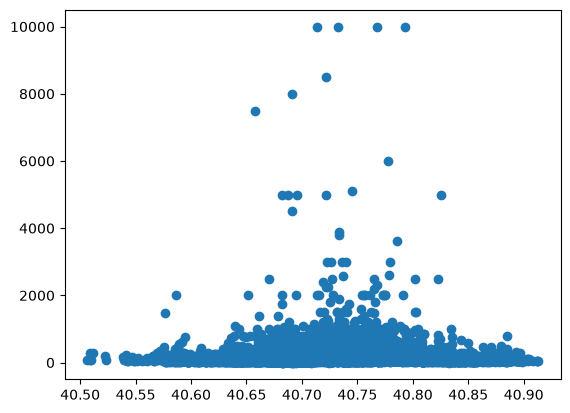

In [12]:
plt.scatter(x= "latitude", y="price", data=df,)

In [13]:
df.query('40.70 < latitude > 40.85' and 'price > 7000')
#9151 , 6530, 12342, 17692
# # maybe 30268 

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
4377,2953058,Film Location,1177497,Jessica,Brooklyn,Clinton Hill,40.69137,-73.96723,Entire home/apt,8000,1,1,2016-09-15,0.03,11,365
6530,4737930,Spanish Harlem Apt,1235070,Olson,Manhattan,East Harlem,40.79264,-73.93898,Entire home/apt,9999,5,1,2015-01-02,0.02,1,0
9151,7003697,Furnished room in Astoria apartment,20582832,Kathrine,Queens,Astoria,40.76810,-73.91651,Private room,10000,100,2,2016-02-13,0.04,1,0
12342,9528920,"Quiet, Clean, Lit @ LES & Chinatown",3906464,Amy,Manhattan,Lower East Side,40.71355,-73.98507,Private room,9999,99,6,2016-01-01,0.14,1,83
17692,13894339,Luxury 1 bedroom apt. -stunning Manhattan views,5143901,Erin,Brooklyn,Greenpoint,40.73260,-73.95739,Entire home/apt,10000,5,5,2017-07-27,0.16,1,0
30268,23377410,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,18128455,Rum,Manhattan,Tribeca,40.72197,-74.00633,Entire home/apt,8500,30,2,2018-09-18,0.18,1,251
45666,34895693,Gem of east Flatbush,262534951,Sandra,Brooklyn,East Flatbush,40.65724,-73.92450,Private room,7500,1,8,2019-07-07,6.15,2,179


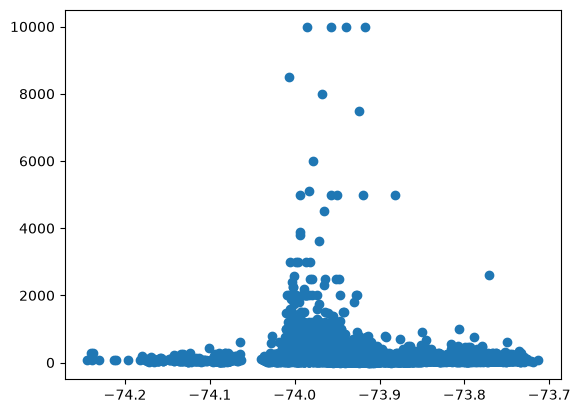

In [14]:
plt.scatter(x= "longitude", y="price", data=df,)

In [15]:
df.query('-74.0 < latitude > -73.9' and 'price > 7000')
# 9151, 6530, 12342, 17692
# maybe 30268 

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
4377,2953058,Film Location,1177497,Jessica,Brooklyn,Clinton Hill,40.69137,-73.96723,Entire home/apt,8000,1,1,2016-09-15,0.03,11,365
6530,4737930,Spanish Harlem Apt,1235070,Olson,Manhattan,East Harlem,40.79264,-73.93898,Entire home/apt,9999,5,1,2015-01-02,0.02,1,0
9151,7003697,Furnished room in Astoria apartment,20582832,Kathrine,Queens,Astoria,40.76810,-73.91651,Private room,10000,100,2,2016-02-13,0.04,1,0
12342,9528920,"Quiet, Clean, Lit @ LES & Chinatown",3906464,Amy,Manhattan,Lower East Side,40.71355,-73.98507,Private room,9999,99,6,2016-01-01,0.14,1,83
17692,13894339,Luxury 1 bedroom apt. -stunning Manhattan views,5143901,Erin,Brooklyn,Greenpoint,40.73260,-73.95739,Entire home/apt,10000,5,5,2017-07-27,0.16,1,0
30268,23377410,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,18128455,Rum,Manhattan,Tribeca,40.72197,-74.00633,Entire home/apt,8500,30,2,2018-09-18,0.18,1,251
45666,34895693,Gem of east Flatbush,262534951,Sandra,Brooklyn,East Flatbush,40.65724,-73.92450,Private room,7500,1,8,2019-07-07,6.15,2,179


In [16]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,3.882100e+04,3.882100e+04,38821.000000,38821.000000,38821.000000,38821.000000,38821.000000,38821.000000,38821.000000,38821.000000
mean,1.810081e+07,6.424582e+07,40.728129,-73.951149,142.332526,5.869220,29.290255,1.373229,5.166611,114.886299
std,1.069372e+07,7.589752e+07,0.054991,0.046693,196.994756,17.389026,48.182900,1.680328,26.302954,129.529950
min,2.539000e+03,2.438000e+03,40.506410,-74.244420,0.000000,1.000000,1.000000,0.010000,1.000000,0.000000
25%,8.721444e+06,7.029525e+06,40.688640,-73.982460,69.000000,1.000000,3.000000,0.190000,1.000000,0.000000
50%,1.887286e+07,2.837092e+07,40.721710,-73.954810,101.000000,2.000000,9.000000,0.720000,1.000000,55.000000
75%,2.756746e+07,1.018905e+08,40.762990,-73.935020,170.000000,4.000000,33.000000,2.020000,2.000000,229.000000
max,3.645581e+07,2.738417e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


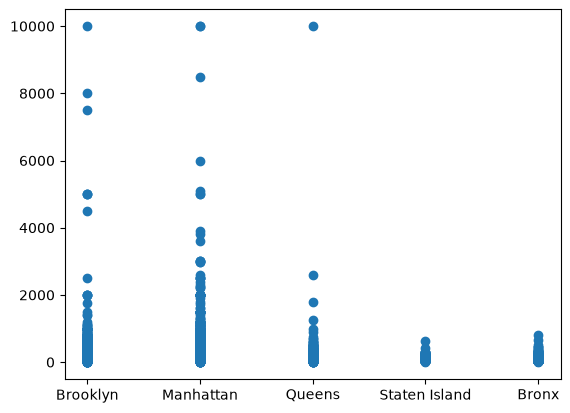

In [17]:
plt.scatter(x= "neighbourhood_group", y="price", data=df,)

In [18]:
df.query('price >= 7500')
# 4377, 6530, 12342, 17692,30268, 45666

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
4377,2953058,Film Location,1177497,Jessica,Brooklyn,Clinton Hill,40.69137,-73.96723,Entire home/apt,8000,1,1,2016-09-15,0.03,11,365
6530,4737930,Spanish Harlem Apt,1235070,Olson,Manhattan,East Harlem,40.79264,-73.93898,Entire home/apt,9999,5,1,2015-01-02,0.02,1,0
9151,7003697,Furnished room in Astoria apartment,20582832,Kathrine,Queens,Astoria,40.76810,-73.91651,Private room,10000,100,2,2016-02-13,0.04,1,0
12342,9528920,"Quiet, Clean, Lit @ LES & Chinatown",3906464,Amy,Manhattan,Lower East Side,40.71355,-73.98507,Private room,9999,99,6,2016-01-01,0.14,1,83
17692,13894339,Luxury 1 bedroom apt. -stunning Manhattan views,5143901,Erin,Brooklyn,Greenpoint,40.73260,-73.95739,Entire home/apt,10000,5,5,2017-07-27,0.16,1,0
30268,23377410,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,18128455,Rum,Manhattan,Tribeca,40.72197,-74.00633,Entire home/apt,8500,30,2,2018-09-18,0.18,1,251
45666,34895693,Gem of east Flatbush,262534951,Sandra,Brooklyn,East Flatbush,40.65724,-73.92450,Private room,7500,1,8,2019-07-07,6.15,2,179


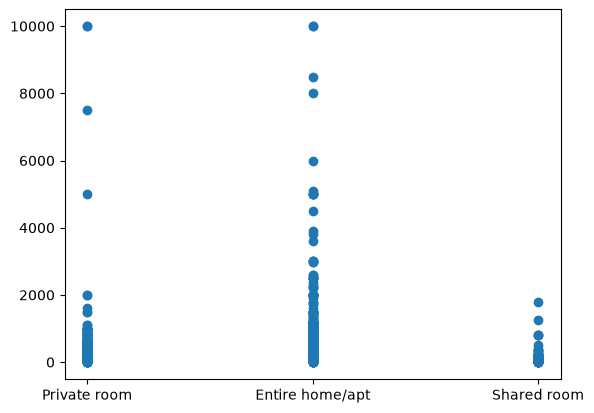

In [19]:
plt.scatter(x= "room_type", y="price", data=df,)

In [20]:
df.query('room_type =private room' and 'price > 4000')

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
2698,1448703,Beautiful 1 Bedroom in Nolita/Soho,213266,Jessica,Manhattan,Nolita,40.72193,-73.99379,Entire home/apt,5000,1,2,2013-09-28,0.03,1,365
3537,2110145,UWS 1BR w/backyard + block from CP,2151325,Jay And Liz,Manhattan,Upper West Side,40.77782,-73.97848,Entire home/apt,6000,14,17,2015-02-17,0.27,1,359
4345,2919330,NearWilliamsburg bridge 11211 BK,14908606,Bianca,Brooklyn,Bedford-Stuyvesant,40.69572,-73.95731,Private room,5000,6,10,2016-01-02,0.16,1,363
4376,2952861,Photography Location,1177497,Jessica,Brooklyn,Clinton Hill,40.69127,-73.96563,Entire home/apt,4500,1,5,2018-12-29,0.09,11,365
4377,2953058,Film Location,1177497,Jessica,Brooklyn,Clinton Hill,40.69137,-73.96723,Entire home/apt,8000,1,1,2016-09-15,0.03,11,365
6530,4737930,Spanish Harlem Apt,1235070,Olson,Manhattan,East Harlem,40.79264,-73.93898,Entire home/apt,9999,5,1,2015-01-02,0.02,1,0
9151,7003697,Furnished room in Astoria apartment,20582832,Kathrine,Queens,Astoria,40.76810,-73.91651,Private room,10000,100,2,2016-02-13,0.04,1,0
12342,9528920,"Quiet, Clean, Lit @ LES & Chinatown",3906464,Amy,Manhattan,Lower East Side,40.71355,-73.98507,Private room,9999,99,6,2016-01-01,0.14,1,83
17692,13894339,Luxury 1 bedroom apt. -stunning Manhattan views,5143901,Erin,Brooklyn,Greenpoint,40.73260,-73.95739,Entire home/apt,10000,5,5,2017-07-27,0.16,1,0
25825,20654227,Fulton 2,100069033,Sarah-2,Brooklyn,Cypress Hills,40.68185,-73.88128,Entire home/apt,5000,2,4,2018-01-03,0.18,1,0


In [21]:
df.query('room_type = Entire home/apt' and 'price > 7700')
# 4377, 6530, 30268

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
4377,2953058,Film Location,1177497,Jessica,Brooklyn,Clinton Hill,40.69137,-73.96723,Entire home/apt,8000,1,1,2016-09-15,0.03,11,365
6530,4737930,Spanish Harlem Apt,1235070,Olson,Manhattan,East Harlem,40.79264,-73.93898,Entire home/apt,9999,5,1,2015-01-02,0.02,1,0
9151,7003697,Furnished room in Astoria apartment,20582832,Kathrine,Queens,Astoria,40.76810,-73.91651,Private room,10000,100,2,2016-02-13,0.04,1,0
12342,9528920,"Quiet, Clean, Lit @ LES & Chinatown",3906464,Amy,Manhattan,Lower East Side,40.71355,-73.98507,Private room,9999,99,6,2016-01-01,0.14,1,83
17692,13894339,Luxury 1 bedroom apt. -stunning Manhattan views,5143901,Erin,Brooklyn,Greenpoint,40.73260,-73.95739,Entire home/apt,10000,5,5,2017-07-27,0.16,1,0
30268,23377410,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,18128455,Rum,Manhattan,Tribeca,40.72197,-74.00633,Entire home/apt,8500,30,2,2018-09-18,0.18,1,251


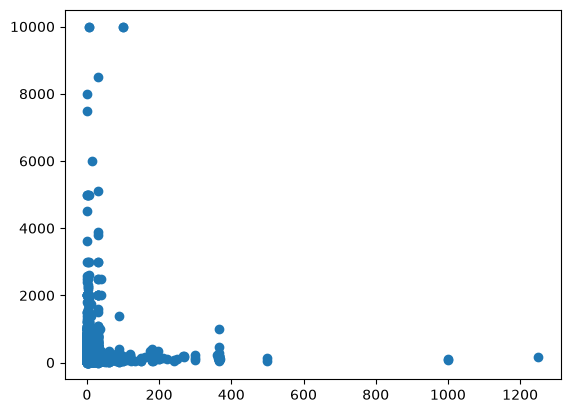

In [22]:
plt.scatter(x= "minimum_nights", y="price", data=df,)

In [23]:
df.query("minimum_nights > 800")
# 5767, 13404, 26341

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
5767,4204302,Prime W. Village location 1 bdrm,17550546,Genevieve,Manhattan,Greenwich Village,40.73293,-73.99782,Entire home/apt,180,1250,2,2014-11-09,0.03,1,365
13404,10053943,Historic Designer 2 Bed. Apartment,2697686,Glenn H.,Manhattan,Harlem,40.82915,-73.94034,Entire home/apt,99,999,2,2018-01-04,0.07,1,42
26341,20990053,Beautiful place in Brooklyn! #2,151084261,Angie,Brooklyn,Williamsburg,40.71772,-73.95059,Private room,79,999,24,2018-06-28,1.12,6,249


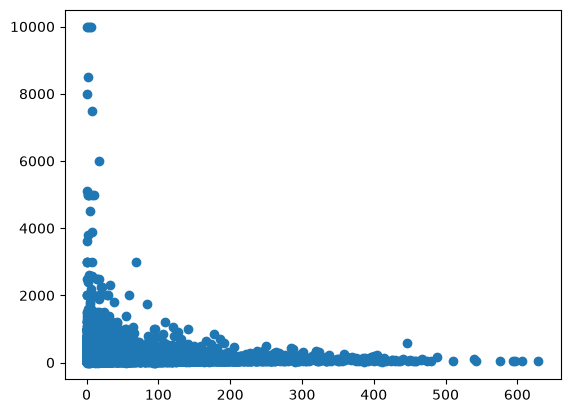

In [24]:
plt.scatter(x= "number_of_reviews", y="price", data=df,)

In [25]:
df.query('number_of_reviews > 550')
# 2015,2030,2031,11759,13495

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
2015,891117,Private Bedroom in Manhattan,4734398,Jj,Manhattan,Harlem,40.82264,-73.94041,Private room,49,1,594,2019-06-15,7.57,3,339
2030,903947,Beautiful Bedroom in Manhattan,4734398,Jj,Manhattan,Harlem,40.82124,-73.93838,Private room,49,1,597,2019-06-23,7.72,3,342
2031,903972,Great Bedroom in Manhattan,4734398,Jj,Manhattan,Harlem,40.82085,-73.94025,Private room,49,1,607,2019-06-21,7.75,3,293
11759,9145202,Room near JFK Queen Bed,47621202,Dona,Queens,Jamaica,40.66730,-73.76831,Private room,47,1,629,2019-07-05,14.58,2,333
13495,10101135,Room Near JFK Twin Beds,47621202,Dona,Queens,Jamaica,40.66939,-73.76975,Private room,47,1,576,2019-06-27,13.40,2,173


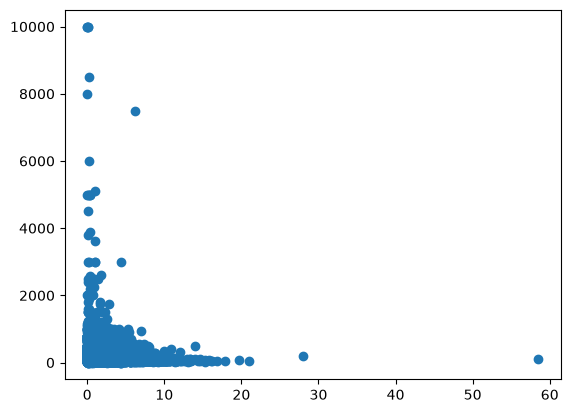

In [26]:
plt.scatter(x= 'reviews_per_month', y= 'price', data=df)

In [27]:
test = df.query('reviews_per_month > 40 ')
# 42075
test

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
42075,32678719,Enjoy great views of the City in our Deluxe Room!,244361589,Row NYC,Manhattan,Theater District,40.75918,-73.98801,Private room,100,1,156,2019-07-07,58.5,9,299


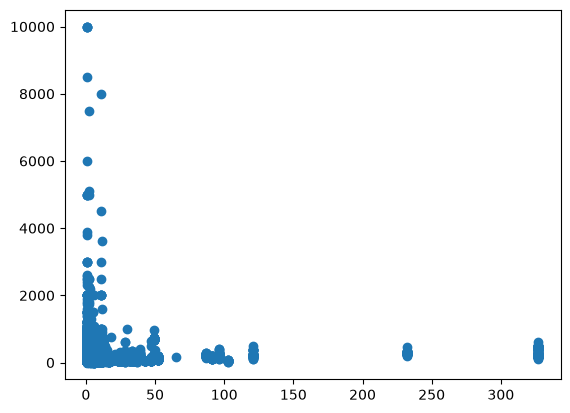

In [28]:
plt.scatter(x = 'calculated_host_listings_count', y = 'price', data=df)

In [29]:
df.query('calculated_host_listings_count > 200')

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
29128,22370388,"Calming FiDi 1BR w/ lux Gym, Speakeasy + Doorm...",107434423,Blueground,Manhattan,Financial District,40.70637,-74.00941,Entire home/apt,271,30,1,2018-08-17,0.09,232,310
30428,23538486,"Posh Park Avenue 1BR w/ Gym, Doorman in Midtow...",107434423,Blueground,Manhattan,Murray Hill,40.74891,-73.97887,Entire home/apt,305,30,1,2019-01-15,0.17,232,326
32788,25823670,"Adorable UES Studio w/ Balcony, Gym + Doorman ...",107434423,Blueground,Manhattan,Upper East Side,40.77669,-73.95673,Entire home/apt,211,30,1,2019-02-28,0.23,232,201
34048,26982403,Enchanting 1BR near Times Sq w/ Indoor pool + ...,107434423,Blueground,Manhattan,Theater District,40.76196,-73.98536,Entire home/apt,280,30,2,2019-05-16,0.36,232,218
35411,28095496,"Roomy FiDi 1BR w/ Gym, Roof deck + Doorman by ...",107434423,Blueground,Manhattan,Financial District,40.70427,-74.00964,Entire home/apt,285,30,1,2018-11-03,0.12,232,324
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44346,34183895,Sonder | Stock Exchange | Intimate 1BR + Kitchen,219517861,Sonder (NYC),Manhattan,Financial District,40.70630,-74.01254,Entire home/apt,247,2,4,2019-06-23,2.35,327,232
44534,34284409,Sonder | 116 John | Modern Studio + Gym,219517861,Sonder (NYC),Manhattan,Financial District,40.70825,-74.00482,Entire home/apt,100,29,1,2019-06-06,0.88,327,358
44670,34341994,Sonder | 116 John | Polished 2BR + Gym,219517861,Sonder (NYC),Manhattan,Financial District,40.70781,-74.00525,Entire home/apt,179,29,1,2019-06-24,1.00,327,339
45148,34566104,Sonder | Stock Exchange | Warm Studio + Lounge,219517861,Sonder (NYC),Manhattan,Financial District,40.70598,-74.01069,Entire home/apt,222,2,1,2019-05-29,0.73,327,315


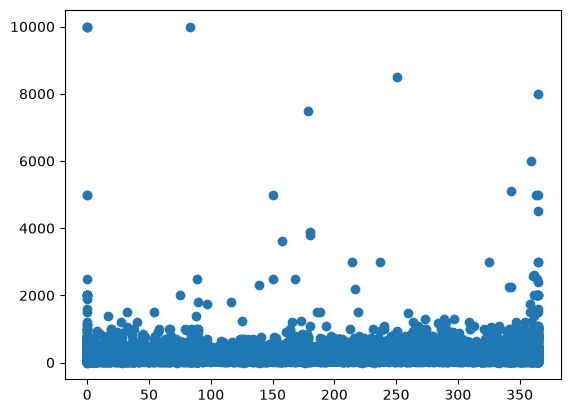

In [30]:
plt.scatter(x= 'availability_365', y = 'price', data= df)

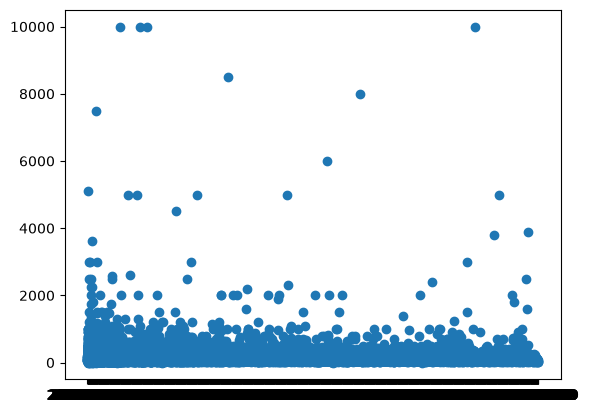

In [31]:
plt.scatter(x= 'last_review', y = 'price', data= df)

In [32]:
long = 73.80
lat = 40.80

locations = list(zip(df.latitude,df.longitude))

map1 = folium.Map(locations=[lat,long], zoom_start=9)
FastMarkerCluster(data=locations).add_to(map1)
print("Visualizing Geographic Locations on an Interactive Map")
map1

Visualizing Geographic Locations on an Interactive Map


In [33]:
# outliers
outliers = [42075, 9151 , 6530, 12342, 17692, 30268, 2015,2030,2031,11759,13495,4377,30268,5767, 13404, 26341]

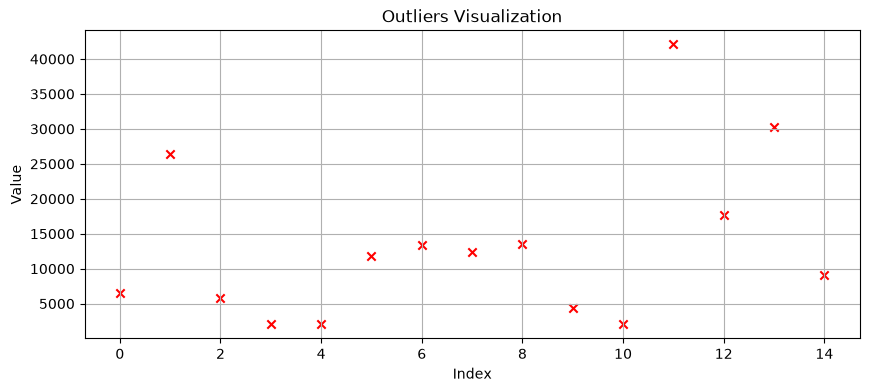

In [34]:
outliers = list(set(outliers))

plt.figure(figsize=(10, 4))
plt.scatter(range(len(outliers)), outliers, color='red', marker='x')
plt.title('Outliers Visualization')
plt.xlabel('Index')
plt.ylabel('Value')
plt.grid(True)
plt.show()

In [35]:
df = df[df.index.isin(outliers) == False]

In [36]:
pd.DataFrame(df.isnull().sum().sort_values(ascending=False)).head(20)

,0
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [37]:
df["neighbourhood"].unique()

<StringArray>
[        'Kensington',            'Midtown',       'Clinton Hill',
        'East Harlem',        'Murray Hill', 'Bedford-Stuyvesant',
     'Hell's Kitchen',    'Upper West Side',          'Chinatown',
        'South Slope',
 ...
          'Unionport',         'Mill Basin',             'Hollis',
      'Arden Heights',        'Bull's Head',          'Olinville',
          'Rossville',       'Breezy Point',        'Willowbrook',
     'New Dorp Beach']
Length: 218, dtype: str

In [38]:
df["neighbourhood_group"].unique()

<StringArray>
['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx']
Length: 5, dtype: str

In [39]:
df["room_type"].unique()

<StringArray>
['Private room', 'Entire home/apt', 'Shared room']
Length: 3, dtype: str

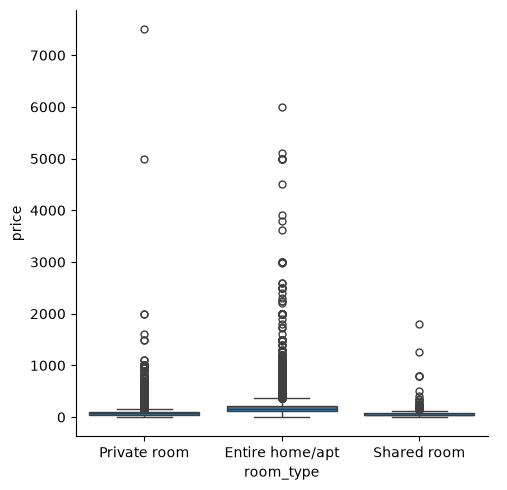

In [40]:
sns.catplot(data=df, x = "room_type", y = "price", kind="box")

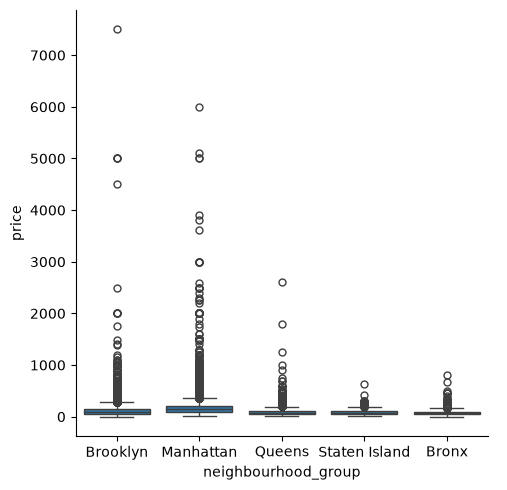

In [41]:
sns.catplot(data=df, x="neighbourhood_group", y="price", kind="box")

In [42]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='str')

In [43]:
df = df.drop(columns=["name","host_id","host_name","neighbourhood","last_review"])

<Axes: >

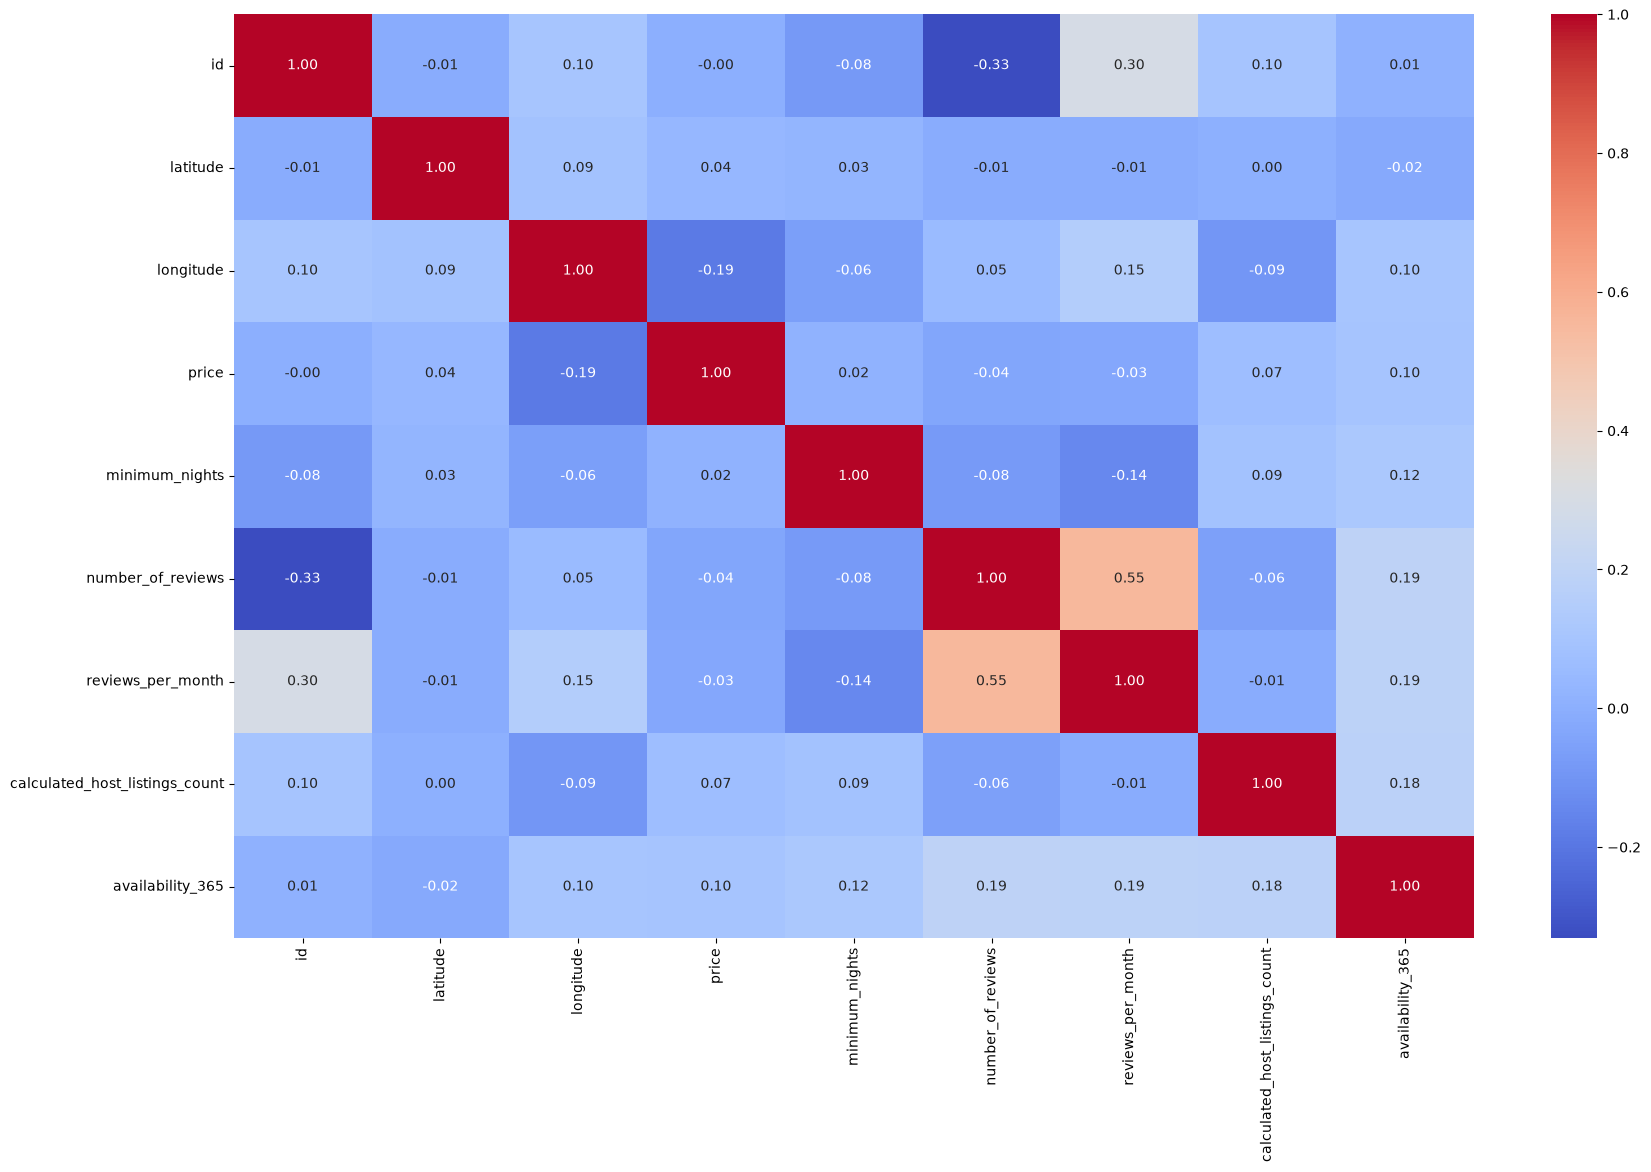

In [44]:
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(20,12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

In [45]:
# drop reviws_per_month or number_of_reviews

In [46]:
df = df.drop(columns=["reviews_per_month"])

In [47]:
df.info()

<class 'pandas.DataFrame'>
Index: 38806 entries, 0 to 48852
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              38806 non-null  int64  
 1   neighbourhood_group             38806 non-null  str    
 2   latitude                        38806 non-null  float64
 3   longitude                       38806 non-null  float64
 4   room_type                       38806 non-null  str    
 5   price                           38806 non-null  int64  
 6   minimum_nights                  38806 non-null  int64  
 7   number_of_reviews               38806 non-null  int64  
 8   calculated_host_listings_count  38806 non-null  int64  
 9   availability_365                38806 non-null  int64  
dtypes: float64(2), int64(6), str(2)
memory usage: 3.3 MB


<Axes: xlabel='price', ylabel='Count'>

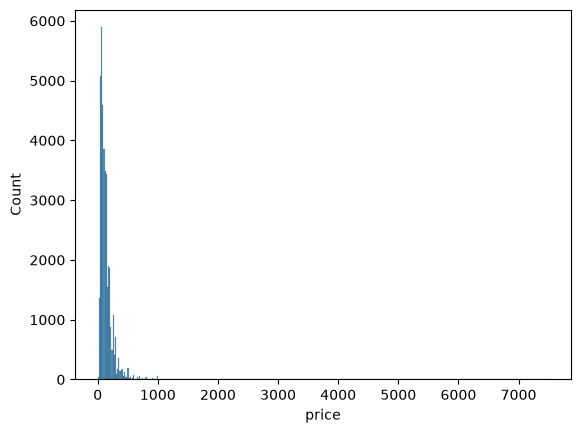

In [48]:
sns.histplot(df,x=df["price"])

<Axes: xlabel='price', ylabel='Count'>

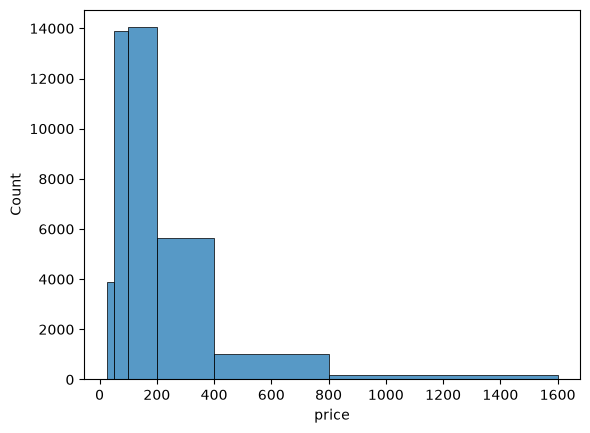

In [49]:
X = [25,50,100,200,400,800,1600]
sns.histplot(df,x=df['price'], bins=X)

In [50]:
df["price"] = np.log1p(df["price"])

<Axes: xlabel='price', ylabel='Count'>

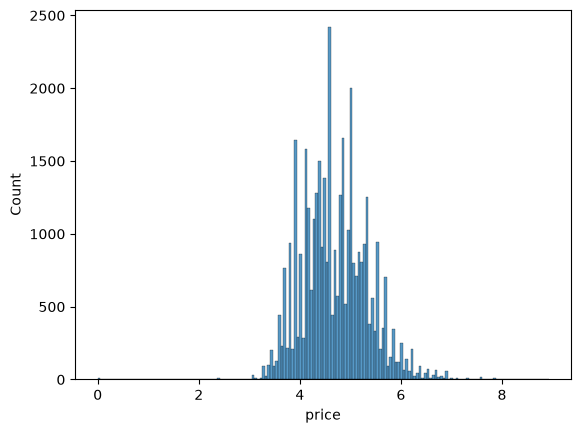

In [51]:
sns.histplot(df,x=df["price"])

In [52]:
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).set_output(transform='pandas')

In [53]:
ohetransform = ohe.fit_transform(df[["neighbourhood_group"]])
ohetransform1 = ohe.fit_transform(df[["room_type"]])

In [54]:
ohetransform

,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island
0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0
5,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...
48782,0.0,0.0,1.0,0.0,0.0
48790,0.0,0.0,0.0,1.0,0.0
48799,0.0,0.0,0.0,0.0,1.0
48805,1.0,0.0,0.0,0.0,0.0


In [55]:
ohetransform1

,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,0.0,1.0,0.0
1,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
5,1.0,0.0,0.0
...,...,...,...
48782,0.0,1.0,0.0
48790,0.0,1.0,0.0
48799,0.0,1.0,0.0
48805,1.0,0.0,0.0


In [56]:
df = pd.concat([df, ohetransform,ohetransform1], axis=1).drop(columns = ['neighbourhood_group','room_type']) 

In [57]:
df.head()

,id,latitude,longitude,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,2539,40.64749,-73.97237,5.010635,1,9,6,365,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2595,40.75362,-73.98377,5.420535,1,45,2,355,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,3831,40.68514,-73.95976,4.499810,1,270,1,194,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,5022,40.79851,-73.94399,4.394449,10,9,1,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
5,5099,40.74767,-73.97500,5.303305,3,74,1,129,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [58]:
X = df.drop(columns = ['price', 'id'])
y = df['price']

In [59]:
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [60]:
# Define Models
Models = {
    "LinearRegression": LinearRegression(),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.33, random_state=42),
    "KNeighborsRegressor": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=40, weights="distance")),
    "GradientBoostingRegressor": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42),
    "SVR": make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.2))  
}

# Evaluate Models
results = []
for name, Model in Models.items():
    Model.fit(X_train, Y_train)
    Y_pred = Model.predict(X_test)
    MAE = mean_absolute_error(Y_test, Y_pred)
    MSE = np.sqrt(mean_squared_error(Y_test, Y_pred))
    R2 = r2_score(Y_test,Y_pred)
    results.append([name,round(MAE, 3), round(MSE, 3), round(R2, 3)])


In [61]:
results_df = pd.DataFrame(results, columns=["Model","MAE", "MSE","R2 Score"])
results_df



,Model,MAE,MSE,R2 Score
0,LinearRegression,0.342,0.464,0.516
1,RandomForestRegressor,0.294,0.407,0.628
2,KNeighborsRegressor,0.307,0.421,0.602
3,GradientBoostingRegressor,0.298,0.412,0.620
4,SVR,0.305,0.425,0.595


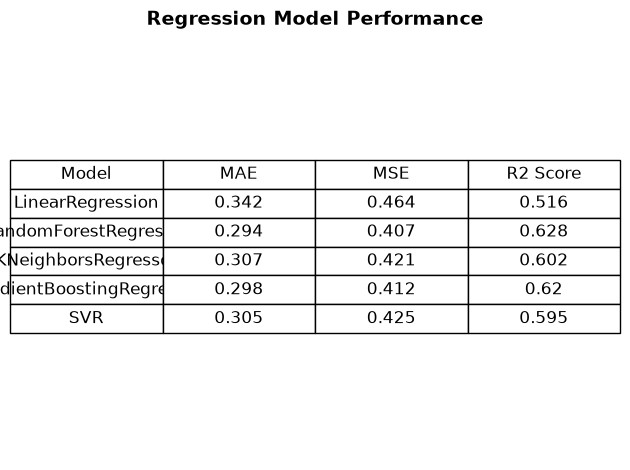

In [62]:
# Plot as a table
fig, ax = plt.subplots()
ax.axis('off')
table = ax.table(
    cellText=results_df.values,
    colLabels=results_df.columns,
    loc='center',
    cellLoc='center'
)
table.scale(1, 1.5)
table.auto_set_font_size(False)
table.set_fontsize(12)
plt.title("Regression Model Performance", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

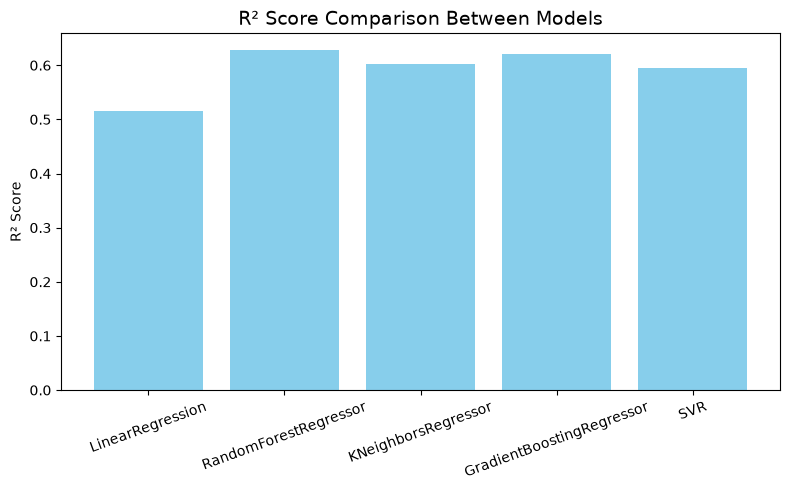

In [63]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["R2 Score"], color='skyblue')
plt.ylabel("R² Score")
plt.title("R² Score Comparison Between Models", fontsize=14)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("regression_r2_barplot.png")  # Save the bar plot as image
plt.show()